# Recaudación por IVA

In [ ]:
# Parámetros de la gráfica
SLUG = "fiscalidad"  # carpeta en research/temas/
GRAFICA_ID = "recaudacion-iva"  # id de la gráfica (kebab-case) = nombre del notebook
TITULO = "Recaudación por IVA"  # `titulo` de la gráfica en config.json
DESDE = 1976  # inicio de la ventana temporal (METODOLOGIA §2.3)
TIPO = "serie_temporal"  # serie_temporal | por_ccaa | solo_espana
VISTA = "lineas"  # `vista` de la gráfica en config.json: lineas | ultimo_anio | proyeccion | categorias
EJE_MAX = None  # `eje_max` de la gráfica en config.json; None = el que piden los datos
UNIDAD = "% del PIB"  # unidad del indicador
CSV_FORMATO = "es"  # CSV: "es" (separador ; y coma decimal, Excel en español) o "int" (, y punto)
CSV_DECIMALES = 2  # decimales del CSV (el JSON guarda el valor completo)
REFERENCIA = None  # línea horizontal de referencia (p. ej. 100 en un índice); None = sin línea
DIR_SALIDA = None  # solo tests; None = temas/<SLUG>/data/

## 1. Contexto

**Qué mide.** Lo que recaudan las administraciones públicas por el impuesto sobre el valor añadido (IVA), en porcentaje del PIB. El IVA grava el consumo: lo paga el consumidor final dentro del precio de los bienes y servicios, y cada empresa ingresa en Hacienda el IVA que cobra en sus ventas menos el que ha pagado en sus compras. Incluye lo recaudado por todas las administraciones, también la parte que se cede a comunidades autónomas y entidades locales.

**Cómo se lee.** Un valor de 7 significa que lo recaudado por IVA ese año equivale al 7 % del PIB.

**Limitaciones.**
- No es un tipo impositivo. El porcentaje depende de los tipos (general y reducidos), de los bienes y servicios exentos, del peso del consumo en el PIB y del IVA que se deja de cobrar por fraude o impago: un país con un tipo general alto puede recaudar poco si aplica muchos tipos reducidos o exenciones.
- La media UE-27 de Eurostat pondera por el tamaño de cada país (IVA total entre PIB total); la media OCDE es una media simple de países, en la que cuentan con 0 los que no tienen IVA, como EE. UU.
- EE. UU. no tiene IVA: su serie queda sin dato.
- España no tenía IVA antes de 1986 ni Canadá antes de 1991: esos años figuran con 0, como los publica la OCDE. La serie de Canadá tiene además una ruptura de clasificación en 2008 (ver notas).
- La media UE-27 empieza en 1995, el primer año que publica Eurostat.
- Son datos con criterios de contabilidad nacional y pueden no coincidir con las cifras de recaudación que publica la Agencia Tributaria, que siguen otro criterio de registro.

## 2. Descarga

- **España, media OCDE, EE. UU. y Canadá:** OCDE, *Revenue Statistics* (`OECD.CTP.TPS,DSD_REV_COMP_OECD@DF_RSOECD`, versión 2.0): ingresos tributarios (`TAX_REV`) del conjunto de las administraciones públicas (`S13`) en la categoría 5111 de la OCDE (impuestos sobre el valor añadido, `T_5111`), en % del PIB (`PT_B1GQ`). La media OCDE es el área `OECD_REP`.
- **UE-27:** Eurostat `gov_10a_taxag`, impuestos del tipo del valor añadido (`D211`) de las administraciones públicas y las instituciones de la UE (`S13_S212`), en % del PIB (`PC_GDP`). Se descarga también España, solo para compararla con la OCDE.

Para las comprobaciones de la sección 3 (no se publican) se descargan además las categorías 5111, 5112 (impuestos sobre las ventas) y 5113 (impuestos sobre el volumen de ventas y otros generales) de todos los países de la OCDE, el desglose de la categoría 5113 en la tabla nacional de España (`DSD_REV_OECD@DF_REVESP`) y la última versión publicada del dataflow.

In [ ]:
import sys
from pathlib import Path

# Raíz del proyecto (la carpeta con global.json y lib/), buscando hacia arriba desde el directorio de ejecución
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "global.json").exists()), None)
if RAIZ is None:
    raise FileNotFoundError(
        "No se encuentra global.json. Abre el notebook desde su carpeta (temas/<tema>/notebooks/) "
        "dentro del repositorio completo; consulta el README para instalar el entorno."
    )
sys.path.insert(0, str(RAIZ))

import pandas as pd

from lib import estilos
from lib.writer import construir_grafica_data, write_grafica_data


import io
import xml.etree.ElementTree as ET
from datetime import date

import requests

from lib import eurostat, oecd
from lib._http import pedir
from lib.tipos import FuenteMeta

# OCDE, Revenue Statistics (países de la OCDE). La versión del dataflow cambia con las ediciones y las
# antiguas dejan de actualizarse: la sección 3 comprueba que esta sea la última publicada.
DATAFLOW = "OECD.CTP.TPS,DSD_REV_COMP_OECD@DF_RSOECD,2.0"
# Clave: REF_AREA.MEASURE.SECTOR.STANDARD_REVENUE.CTRY_SPECIFIC_REVENUE.UNIT_MEASURE.FREQ
#   TAX_REV: ingresos tributarios · S13: administraciones públicas · T_5111: impuestos sobre el valor añadido
#   _T: sin desglose nacional · PT_B1GQ: % del PIB · A: anual
CLAVE = "{AREA}.TAX_REV.S13.T_5111._T.PT_B1GQ.A"
# OECD_REP («OECD average country») es la media de la OCDE; EE. UU. se descarga para comprobar que es 0
AREAS = {"ESP": "espana", "OECD_REP": "ocde", "USA": "eeuu", "CAN": "canada"}
# Eurostat: IVA (D211) de las administraciones públicas y las instituciones de la UE, % del PIB
FILTROS_EUROSTAT = {"freq": "A", "unit": "PC_GDP", "sector": "S13_S212", "na_item": "D211"}
# Tabla nacional de España en Revenue Statistics (solo comprobaciones: qué impuestos hay en la categoría 5113)
DATAFLOW_ESP = "OECD.CTP.TPS,DSD_REV_OECD@DF_REVESP,2.0"


def descargar():
    """Devuelve las series de la OCDE y las de Eurostat, cada una con sus FuenteMeta."""
    ocde_df, f_ocde = oecd.get(DATAFLOW, CLAVE, areas=AREAS, desde=DESDE)
    euro_df, f_euro = eurostat.get(
        "gov_10a_taxag", FILTROS_EUROSTAT, geos={"ES": "espana_eurostat", "EU27_2020": "ue27"}, desde=DESDE
    )
    return ocde_df, f_ocde, euro_df, f_euro


def descargar_comprobacion():
    """Solo para comprobar: categorías 5111, 5112 y 5113 de todas las áreas, en % del PIB."""
    clave = ".TAX_REV.S13.T_5111+T_5112+T_5113._T.PT_B1GQ.A"
    r = pedir(
        requests.Session(), f"{oecd.BASE}/{DATAFLOW}/{clave}", {"startPeriod": str(DESDE)},
        error_cls=oecd.OecdError, etiqueta="comprobación", mensaje=lambda r: r.text[:200],
        headers=oecd.CABECERA_CSV,
    )
    crudo = pd.read_csv(io.StringIO(r.text), dtype={"REF_AREA": str, "STANDARD_REVENUE": str})
    return crudo.pivot_table(index="TIME_PERIOD", columns=["STANDARD_REVENUE", "REF_AREA"], values="OBS_VALUE")


def desglose_espana():
    """Solo para comprobar: desglose nacional de la categoría 5113 de España (millones de euros, por año)."""
    r = pedir(
        requests.Session(), f"{oecd.BASE}/{DATAFLOW_ESP}/ESP.TAX_REV.S13.T_5113...A", {"startPeriod": str(DESDE)},
        error_cls=oecd.OecdError, etiqueta="desglose España", mensaje=lambda r: r.text[:200],
        headers={"Accept": "application/vnd.sdmx.data+csv;version=1.0.0;labels=both"},
    )
    crudo = pd.read_csv(io.StringIO(r.text))
    crudo.columns = [c.split(":")[0] for c in crudo.columns]  # cabeceras «CÓDIGO: nombre» → «CÓDIGO»; los valores conservan el nombre
    return crudo.pivot_table(index="CTRY_SPECIFIC_REVENUE", columns="TIME_PERIOD", values="OBS_VALUE")


def ultima_version():
    """Versión más reciente del dataflow publicada por la OCDE."""
    agencia, flujo, _ = DATAFLOW.split(",")
    url = oecd.BASE.removesuffix("/data") + f"/dataflow/{agencia}/{flujo}/latest"
    r = pedir(
        requests.Session(), url, None, error_cls=oecd.OecdError, etiqueta="versión",
        mensaje=lambda r: r.text[:200],
    )
    ns = {"s": "http://www.sdmx.org/resources/sdmxml/schemas/v2_1/structure"}
    return ET.fromstring(r.content).find(".//s:Dataflow", ns).get("version")


ocde_df, f_ocde, euro_df, f_euro = descargar()
comp = descargar_comprobacion()
desglose_esp = desglose_espana()
version_ultima = ultima_version()

## 3. Transformación

La OCDE y Eurostat ya publican el IVA en % del PIB: no hay deflactor, cambio de unidades ni enlace de series. Se toman España, la media OCDE y Canadá de la OCDE y la UE-27 de Eurostat. EE. UU., que no tiene IVA (la OCDE publica 0 todos los años), queda sin dato, con la fuente consultada. Los años anteriores a la introducción del IVA en España (1986) y Canadá (1991) se dejan con el 0 que publica la OCDE.

In [ ]:
def anadir_sin_dato(df, fuentes, sin_dato):
    """Añade las series de la cesta sin dato comparable (todo `null`) con la fuente consultada."""
    hoy = date.today().isoformat()
    vacias = pd.DataFrame({"serie": list(sin_dato), "periodo": DESDE, "valor": float("nan")})
    extra = [FuenteMeta(s, org, cod, url, hoy) for s, (org, cod, url) in sin_dato.items()]
    return pd.concat([df, vacias], ignore_index=True), [*fuentes, *extra]


assert ocde_df["valor"].between(0, 20).all() and euro_df["valor"].between(0, 20).all(), "el IVA es un % del PIB"
eeuu = ocde_df.loc[ocde_df["serie"] == "eeuu", "valor"]
assert len(eeuu) and (eeuu == 0).all(), "EE. UU. no tiene IVA: la OCDE debería publicar 0 en todos los años"

_, FLUJO, VERSION = DATAFLOW.split(",")
CODIGO_OCDE = f"{FLUJO} (Revenue Statistics, versión {VERSION}): TAX_REV, S13, T_5111, PT_B1GQ"
CODIGO_EUROSTAT = f"gov_10a_taxag: {FILTROS_EUROSTAT['sector']}, {FILTROS_EUROSTAT['unit']}, {FILTROS_EUROSTAT['na_item']}"
df = pd.concat(
    [ocde_df[ocde_df["serie"].isin(["espana", "ocde", "canada"])], euro_df[euro_df["serie"] == "ue27"]],
    ignore_index=True,
)
fuentes = [
    FuenteMeta(f.serie, f.organismo, CODIGO_OCDE + ("; área OECD_REP" if f.serie == "ocde" else ""), f.url, f.fecha_consulta)
    for f in f_ocde if f.serie in ("espana", "ocde", "canada")
] + [FuenteMeta(f.serie, f.organismo, CODIGO_EUROSTAT, f.url, f.fecha_consulta) for f in f_euro if f.serie == "ue27"]
SIN_IVA_EEUU = (oecd.ORGANISMO, f"{CODIGO_OCDE} (consultada: EE. UU. no tiene IVA)", oecd.URL_EXPLORER)
df, fuentes = anadir_sin_dato(df, fuentes, {"eeuu": SIN_IVA_EEUU})
df.pivot(index="periodo", columns="serie", values="valor").dropna(how="all").round(2).tail(12)

serie,canada,eeuu,espana,ocde,ue27
periodo,,,,,
2013,4.12,NaN,5.88,6.45,6.9
2014,4.14,NaN,6.17,6.56,6.9
2015,4.36,NaN,6.37,6.55,6.9
2016,4.46,NaN,6.39,6.60,7.0
2017,4.51,NaN,6.46,6.67,7.0
2018,4.53,NaN,6.54,6.72,7.1
2019,4.49,NaN,6.45,6.70,7.1
2020,4.53,NaN,6.26,6.66,6.9
2021,4.66,NaN,6.76,6.92,7.3


### Comprobaciones

No cambian los datos publicados:
1. Que la versión fijada del dataflow sea la última que publica la OCDE.
2. España en las dos fuentes: OCDE (la que se publica) y Eurostat, desde 1995.
3. Cómo se calcula la media OCDE: media simple de los países con dato cada año, en la que los países sin IVA cuentan con 0, y cuánto cambia sin EE. UU.
4. Los años sin IVA de España y Canadá (y qué impuestos recogía en España la categoría 5113 antes del IVA), la ruptura de Canadá en 2008 y los impuestos sobre las ventas de EE. UU., con las categorías 5112 y 5113.
5. La distancia de España a la media UE-27 y a la media OCDE cada año.

In [ ]:
def coma(x, decimales=1):
    """Número con coma decimal para los textos (0,5)."""
    return f"{x:.{decimales}f}".replace(".", ",")


# 1) Versión del dataflow
version = DATAFLOW.rsplit(",", 1)[1]
if version_ultima != version:
    print(f"AVISO: la OCDE publica la versión {version_ultima} del dataflow y aquí se usa la {version}: actualiza DATAFLOW.")
else:
    print(f"La versión usada del dataflow ({version}) es la última publicada por la OCDE.")

# 2) España: OCDE frente a Eurostat (que publica un decimal)
esp = pd.DataFrame({
    "OCDE": ocde_df[ocde_df["serie"] == "espana"].set_index("periodo")["valor"],
    "Eurostat": euro_df[euro_df["serie"] == "espana_eurostat"].set_index("periodo")["valor"],
}).dropna()
esp["diferencia"] = esp["OCDE"] - esp["Eurostat"]
dif_max_esp = esp["diferencia"].abs().max()
print(f"España, {esp.index.min()}-{esp.index.max()}: diferencia máxima OCDE - Eurostat = {dif_max_esp:.3f} puntos")
esp.round(3)

La versión usada del dataflow (2.0) es la última publicada por la OCDE.
España, 1995-2024: diferencia máxima OCDE - Eurostat = 0.048 puntos


,OCDE,Eurostat,diferencia
periodo,,,
1995,4.980,5.0,-0.020
1996,5.115,5.1,0.015
1997,5.297,5.3,-0.003
1998,5.593,5.6,-0.007
1999,5.892,5.9,-0.008
2000,5.835,5.8,0.035
2001,5.722,5.7,0.022
2002,5.558,5.6,-0.042
2003,5.687,5.7,-0.013


In [ ]:
# 3) Media OCDE (OECD_REP) recalculada como media simple de los países con dato cada año
iva = comp["T_5111"]
paises = [a for a in iva.columns if a != "OECD_REP" and len(a) == 3 and a.isalpha()]
media = pd.DataFrame({
    "países con dato": iva[paises].notna().sum(axis=1),
    "media calculada": iva[paises].mean(axis=1),
    "OECD_REP": iva["OECD_REP"],
    "países con 0": iva[paises].eq(0).sum(axis=1),
})
con_rep = media.dropna(subset=["OECD_REP"])
assert (con_rep["media calculada"] - con_rep["OECD_REP"]).abs().max() < 0.001, "OECD_REP no es la media simple"
n_paises = len(paises)
n_inicio = int(media.loc[DESDE, "países con dato"])
completos = con_rep["países con dato"] == n_paises
anio_completo = int(completos[~completos].index.max() + 1) if (~completos).any() else int(con_rep.index.min())
ultimo_rep = int(con_rep.index.max())
fila = iva.loc[ultimo_rep, paises]
assert list(fila[fila == 0].index) == ["USA"], "en el último año solo EE. UU. debería contar con 0"
media_sin_eeuu = fila.drop("USA").mean()
pendientes_ocde = [p for p in paises if pd.isna(iva.loc[ultimo_rep + 1, p])] if ultimo_rep + 1 in iva.index else []
print(f"{n_paises} países; {n_inicio} con dato en {DESDE}; todos desde {anio_completo}")
print(f"Media OCDE {ultimo_rep}: {con_rep.loc[ultimo_rep, 'OECD_REP']:.2f}; sin EE. UU.: {media_sin_eeuu:.2f}")
if pendientes_ocde:
    print(f"Sin dato en {ultimo_rep + 1}: {', '.join(pendientes_ocde)} (por eso no hay media OCDE de ese año)")
media[media.index >= DESDE].round(3)

38 países; 22 con dato en 1976; todos desde 1995
Media OCDE 2023: 6.83; sin EE. UU.: 7.01
Sin dato en 2024: AUS, GRC (por eso no hay media OCDE de ese año)


,países con dato,media calculada,OECD_REP,países con 0
TIME_PERIOD,,,,
1976,22,3.403,3.403,9
1977,22,3.554,3.554,8
1978,22,3.795,3.795,8
1979,22,3.814,3.814,8
1980,24,3.663,3.663,9
1981,24,3.724,3.724,9
1982,24,3.735,3.735,9
1983,24,3.844,3.844,9
1984,24,3.897,3.897,9


In [ ]:
# 4) Años sin IVA y otras categorías de impuestos generales sobre el consumo (% del PIB)
otras = pd.DataFrame({
    "España 5111 (IVA)": comp[("T_5111", "ESP")],
    "España 5113 (volumen de ventas)": comp[("T_5113", "ESP")],
    "Canadá 5111 (IVA)": comp[("T_5111", "CAN")],
    "Canadá 5112 (ventas)": comp[("T_5112", "CAN")],
    "EE. UU. 5112 (ventas)": comp[("T_5112", "USA")],
})
iva_esp, iva_can, ventas_can = otras["España 5111 (IVA)"], otras["Canadá 5111 (IVA)"], otras["Canadá 5112 (ventas)"]
anio_iva_esp = int(iva_esp[iva_esp > 0].index.min())
anio_iva_can = int(iva_can[iva_can > 0].index.min())
assert (anio_iva_esp, anio_iva_can) == (1986, 1991), "los textos dicen que el IVA llega en 1986 (España) y 1991 (Canadá)"
assert (iva_esp.loc[DESDE:anio_iva_esp - 1] == 0).all() and (iva_can.loc[DESDE:anio_iva_can - 1] == 0).all()
# Ruptura de Canadá: el año en que más cae la categoría 5112 desde que existe el impuesto federal (GST)
caida = ventas_can.loc[anio_iva_can:].diff()
anio_ruptura = int(caida.idxmin())
assert anio_ruptura == 2008, "el contexto habla de una ruptura de Canadá en 2008"
antes = anio_ruptura - 1
suma_can = iva_can + ventas_can
ultimo_ventas_eeuu = int(otras["EE. UU. 5112 (ventas)"].dropna().index.max())
# Qué recogía la categoría 5113 de España el año anterior al IVA (millones de euros)
sin_iva_esp = desglose_esp[anio_iva_esp - 1].dropna()
componentes_5113 = sin_iva_esp[~sin_iva_esp.index.str.startswith("_T")]
assert componentes_5113.idxmax().startswith("L_3298"), "el mayor componente debería ser el impuesto en cascada (tráfico de las empresas)"
print(f"España, categoría 5113 en {anio_iva_esp - 1} (millones de euros):")
print(sin_iva_esp.sort_values(ascending=False).round(0).to_string())
print(f"España: IVA desde {anio_iva_esp}; 5113 en {anio_iva_esp - 1}: {otras.loc[anio_iva_esp - 1, 'España 5113 (volumen de ventas)']:.2f}")
print(f"Canadá: IVA desde {anio_iva_can}; 5112 en {anio_iva_can - 1}: {ventas_can.loc[anio_iva_can - 1]:.2f}")
print(f"Canadá {antes}->{anio_ruptura}: 5111 {iva_can.loc[antes]:.2f}->{iva_can.loc[anio_ruptura]:.2f}; "
      f"5112 {ventas_can.loc[antes]:.2f}->{ventas_can.loc[anio_ruptura]:.2f}; suma {suma_can.loc[antes]:.2f}->{suma_can.loc[anio_ruptura]:.2f}")
otras.loc[DESDE:].round(2)

España, categoría 5113 en 1985 (millones de euros):
CTRY_SPECIFIC_REVENUE
_T: Total                                7285.0
L_3298: Cascade tax                      5736.0
L_3299: Excises on luxury expenditure    1742.0
L_2508: Other import duties              1707.0
L_3301: Refund of internal taxes        -1899.0
España: IVA desde 1986; 5113 en 1985: 3.95
Canadá: IVA desde 1991; 5112 en 1990: 4.95
Canadá 2007->2008: 5111 2.92->3.85; 5112 1.60->0.16; suma 4.52->4.01


,España 5111 (IVA),España 5113 (volumen de ventas),Canadá 5111 (IVA),Canadá 5112 (ventas),EE. UU. 5112 (ventas)
TIME_PERIOD,,,,,
1976,0.00,2.71,0.00,3.95,1.72
1977,0.00,2.68,0.00,3.97,1.74
1978,0.00,2.90,0.00,3.51,1.76
1979,0.00,2.89,0.00,3.48,1.77
1980,0.00,2.23,0.00,3.50,1.80
1981,0.00,2.38,0.00,3.53,1.73
1982,0.00,2.79,0.00,3.47,1.81
1983,0.00,3.03,0.00,3.65,1.79
1984,0.00,3.52,0.00,3.81,1.86


In [ ]:
# 5) Distancia de España a las medias (puntos del PIB y España en % de cada media), para decidir si pasa a la web
ancho = df.pivot(index="periodo", columns="serie", values="valor")
distancia = pd.DataFrame({
    "España": ancho["espana"],
    "UE-27": ancho["ue27"],
    "España - UE-27": ancho["espana"] - ancho["ue27"],
    "España / UE-27 (%)": ancho["espana"] / ancho["ue27"] * 100,
    "Media OCDE": ancho["ocde"],
    "España - OCDE": ancho["espana"] - ancho["ocde"],
    "España / OCDE (%)": ancho["espana"] / ancho["ocde"] * 100,
}).loc[anio_iva_esp:]  # desde que España tiene IVA
distancia.round(2)

,España,UE-27,España - UE-27,España / UE-27 (%),Media OCDE,España - OCDE,España / OCDE (%)
periodo,,,,,,,
1986,4.15,NaN,NaN,NaN,4.31,-0.16,96.26
1987,4.79,NaN,NaN,NaN,4.83,-0.04,99.21
1988,4.93,NaN,NaN,NaN,4.85,0.08,101.66
1989,5.17,NaN,NaN,NaN,4.68,0.50,110.66
1990,4.96,NaN,NaN,NaN,5.06,-0.10,98.10
1991,4.96,NaN,NaN,NaN,5.03,-0.07,98.61
1992,5.32,NaN,NaN,NaN,5.12,0.19,103.77
1993,4.67,NaN,NaN,NaN,5.33,-0.66,87.69
1994,5.03,NaN,NaN,NaN,5.53,-0.50,90.90


In [ ]:
NOMBRES_PAIS = {
    "AUS": "Australia", "AUT": "Austria", "BEL": "Bélgica", "CAN": "Canadá", "CHE": "Suiza", "CHL": "Chile",
    "COL": "Colombia", "CRI": "Costa Rica", "CZE": "Chequia", "DEU": "Alemania", "DNK": "Dinamarca",
    "ESP": "España", "EST": "Estonia", "FIN": "Finlandia", "FRA": "Francia", "GBR": "Reino Unido",
    "GRC": "Grecia", "HUN": "Hungría", "IRL": "Irlanda", "ISL": "Islandia", "ISR": "Israel", "ITA": "Italia",
    "JPN": "Japón", "KOR": "Corea del Sur", "LTU": "Lituania", "LUX": "Luxemburgo", "LVA": "Letonia",
    "MEX": "México", "NLD": "Países Bajos", "NOR": "Noruega", "NZL": "Nueva Zelanda", "POL": "Polonia",
    "PRT": "Portugal", "SVK": "Eslovaquia", "SVN": "Eslovenia", "SWE": "Suecia", "TUR": "Turquía",
    "USA": "Estados Unidos",
}


def unir(xs):
    """«A», «A y B», «A, B y C»."""
    xs = [str(x) for x in xs]
    return xs[0] if len(xs) == 1 else f"{', '.join(xs[:-1])} y {xs[-1]}"


ultimo_esp = int(df.loc[(df["serie"] == "espana") & df["valor"].notna(), "periodo"].max())
NOTAS = [
    f"España, media OCDE y Canadá: OCDE, Revenue Statistics ({FLUJO}, versión {VERSION}), categoría 5111 (impuestos sobre el valor añadido), "
    "recaudada por el conjunto de las administraciones públicas, en porcentaje del PIB.",
    "Media UE-27: Eurostat gov_10a_taxag, impuestos del tipo del valor añadido (D211) de las administraciones públicas y las instituciones de la UE, "
    "en porcentaje del PIB. Es el agregado de composición actual (EU27_2020), ponderado por tamaño: IVA total de los 27 entre su PIB total. "
    "Eurostat lo publica con un decimal y desde 1995; los años anteriores quedan sin dato.",
    f"Media OCDE: media simple, sin ponderar, de los países que hoy son miembros de la OCDE con dato en cada año "
    f"(área OECD_REP): {n_inicio} países en {DESDE} y los {n_paises} desde {anio_completo}.",
    f"En la media OCDE, los países sin IVA que tienen dato cuentan con 0: EE. UU. todos los años y otros hasta que lo introdujeron, como España hasta {anio_iva_esp - 1} o Canadá hasta {anio_iva_can - 1}. "
    f"Sin EE. UU., la media de {ultimo_rep} sería del {coma(media_sin_eeuu)} % del PIB en lugar del {coma(con_rep.loc[ultimo_rep, 'OECD_REP'])} %.",
    f"España introdujo el IVA en {anio_iva_esp}, al entrar en la Comunidad Europea; hasta {anio_iva_esp - 1} la OCDE registra 0 en esta categoría. "
    "Los impuestos a los que sustituyó el IVA figuran en otra categoría de la OCDE (5113, impuestos sobre el volumen de ventas y otros generales): "
    "el impuesto general sobre el tráfico de las empresas (un impuesto en cascada, el mayor), el impuesto sobre el lujo y otros gravámenes sobre las importaciones. "
    f"En {anio_iva_esp - 1} esa categoría sumó el {coma(otras.loc[anio_iva_esp - 1, 'España 5113 (volumen de ventas)'])} % del PIB, "
    "descontadas las devoluciones de impuestos interiores; no se incluye en la gráfica.",
    f"Canadá introdujo en {anio_iva_can} su impuesto equivalente al IVA, el impuesto federal sobre bienes y servicios (GST); hasta {anio_iva_can - 1} la OCDE registra 0 en esta categoría, "
    f"y los impuestos sobre las ventas (categoría 5112, federales y provinciales) recaudaron el {coma(ventas_can.loc[anio_iva_can - 1])} % del PIB en {anio_iva_can - 1}. "
    "La serie de Canadá suma el impuesto federal y los provinciales que la OCDE clasifica como IVA.",
    f"Ruptura de serie en Canadá en {anio_ruptura}: la OCDE pasa a clasificar como IVA (5111) la mayor parte de lo que hasta {antes} registraba como impuestos "
    f"provinciales sobre las ventas (5112, que baja del {coma(ventas_can.loc[antes])} al {coma(ventas_can.loc[anio_ruptura])} % del PIB). "
    f"La subida de la serie ese año (del {coma(iva_can.loc[antes])} al {coma(iva_can.loc[anio_ruptura])} %) se debe a ese cambio: "
    f"la suma de las dos categorías baja del {coma(suma_can.loc[antes])} al {coma(suma_can.loc[anio_ruptura])} %.",
    f"Estados Unidos no tiene IVA (la OCDE registra 0 en la categoría 5111 todos los años); sus impuestos estatales y locales sobre las ventas "
    f"(categoría 5112, el {coma(otras.loc[ultimo_ventas_eeuu, 'EE. UU. 5112 (ventas)'])} % del PIB en {ultimo_ventas_eeuu}) gravan las ventas al consumidor final "
    "y no son equivalentes, así que la serie queda sin dato.",
]
if dif_max_esp <= 0.05 + 1e-9:
    NOTAS.append(
        f"España: la serie de la OCDE coincide con la de Eurostat (gov_10a_taxag, D211) en todos los años desde {esp.index.min()}, "
        f"salvo el redondeo a un decimal de Eurostat (diferencia máxima de {coma(dif_max_esp, 2)} puntos)."
    )
else:
    NOTAS.append(
        f"España: la serie de la OCDE difiere de la de Eurostat (gov_10a_taxag, D211) hasta en {coma(dif_max_esp, 2)} puntos "
        f"en {esp.index.min()}-{esp.index.max()}; la gráfica usa la de la OCDE."
    )
if ultimo_rep < ultimo_esp:
    NOTAS.append(
        f"La OCDE no publica todavía la media de {ultimo_rep + 1}: faltan los datos de {len(pendientes_ocde)} de sus "
        f"{n_paises} países miembros ({unir(NOMBRES_PAIS.get(p, p) for p in pendientes_ocde)})."
    )
for n in NOTAS:
    print("-", n)

- España, media OCDE y Canadá: OCDE, Revenue Statistics (DSD_REV_COMP_OECD@DF_RSOECD, versión 2.0), categoría 5111 (impuestos sobre el valor añadido), recaudada por el conjunto de las administraciones públicas, en porcentaje del PIB.
- Media UE-27: Eurostat gov_10a_taxag, impuestos del tipo del valor añadido (D211) de las administraciones públicas y las instituciones de la UE, en porcentaje del PIB. Es el agregado de composición actual (EU27_2020), ponderado por tamaño: IVA total de los 27 entre su PIB total. Eurostat lo publica con un decimal y desde 1995; los años anteriores quedan sin dato.
- Media OCDE: media simple, sin ponderar, de los países que hoy son miembros de la OCDE con dato en cada año (área OECD_REP): 22 países en 1976 y los 38 desde 1995.
- En la media OCDE, los países sin IVA que tienen dato cuentan con 0: EE. UU. todos los años y otros hasta que lo introdujeron, como España hasta 1985 o Canadá hasta 1990. Sin EE. UU., la media de 2023 sería del 7,0 % del PIB en lugar

## 4. Visualización

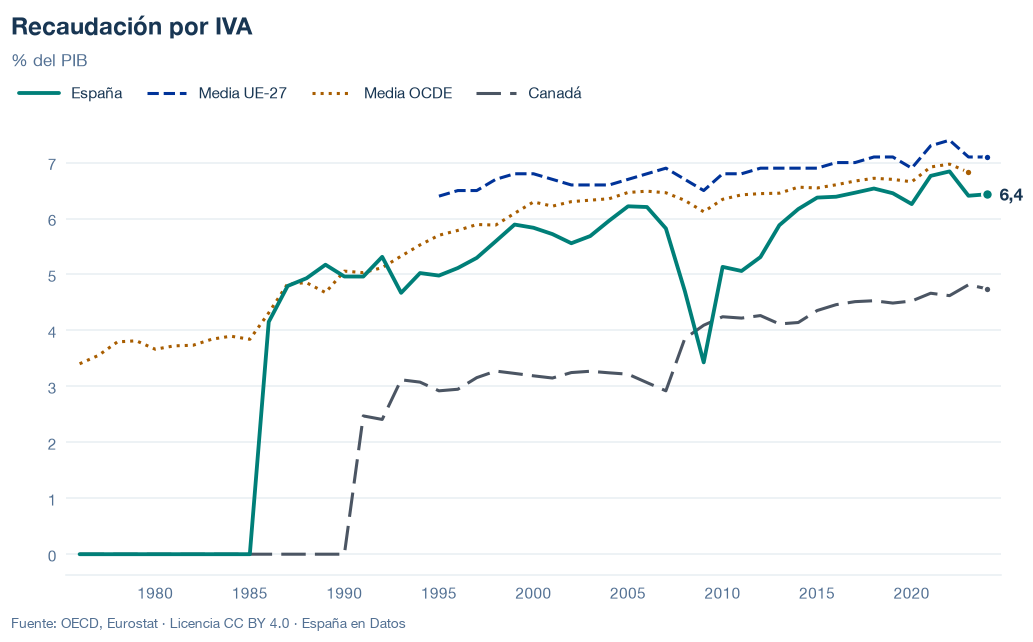

In [ ]:
datos = construir_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA,
)
fig = estilos.figura(datos, titulo=TITULO, vista=VISTA, eje_max=EJE_MAX)
estilos.mostrar(fig)

## 5. Exportación

Escribe `data/<id>.json` (validado contra el esquema) y `data/<id>.csv`, el mismo CSV que se descarga en la web.

In [ ]:
salida = Path(DIR_SALIDA) if DIR_SALIDA else RAIZ / "temas" / SLUG / "data"
ruta = write_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA,
    path=salida / f"{GRAFICA_ID}.json", csv_formato=CSV_FORMATO, csv_decimales=CSV_DECIMALES,
)
print(f"escrito: data/{ruta.name} y data/{ruta.stem}.csv")  # sin rutas locales en las salidas publicadas

escrito: data/recaudacion-iva.json y data/recaudacion-iva.csv


## 6. Fuentes, notas y licencia

- OCDE, *Revenue Statistics* (`OECD.CTP.TPS,DSD_REV_COMP_OECD@DF_RSOECD`, versión 2.0): categoría 5111 (publicada) y categorías 5112 y 5113 (comprobaciones); tabla nacional de España (`DSD_REV_OECD@DF_REVESP`, versión 2.0) para el desglose de la categoría 5113 (comprobación).
- Eurostat, `gov_10a_taxag` (`D211`): UE-27 (publicada) y España (comprobación).

La fecha de consulta de cada serie está en `fuentes` del JSON; las notas, en `notas`, incluyen el primer año con dato de cada serie.

**Licencia:** datos, gráficos y textos CC BY 4.0; código MIT. Cita a España en Datos.